## Доступные GPU

In [1]:
import csv
import io
import subprocess

fields = ["index", "name", "memory.total", "memory.used", "utilization.gpu", "temperature.gpu"]

result = subprocess.run(
    ["nvidia-smi", f"--query-gpu={','.join(fields)}", "--format=csv,noheader"],
    capture_output=True,
    text=True,
    check=True,
    timeout=15,
)

for row in csv.reader(io.StringIO(result.stdout), skipinitialspace=True):
    gpu = dict(zip(fields, row))

    print(f"GPU {gpu['index']}: {gpu['name']}")
    print(f"  Память:     {gpu['memory.used']} / {gpu['memory.total']}")
    print(f"  Загрузка:   {gpu['utilization.gpu']}")
    print(f"  Температура: {gpu['temperature.gpu']} °C")
    print()

GPU 0: NVIDIA RTX A4000
  Память:     6753 MiB / 16376 MiB
  Загрузка:   0 %
  Температура: 29 °C

GPU 1: NVIDIA RTX A4000
  Память:     11481 MiB / 16376 MiB
  Загрузка:   0 %
  Температура: 28 °C

GPU 2: NVIDIA RTX A4000
  Память:     12865 MiB / 16376 MiB
  Загрузка:   100 %
  Температура: 80 °C

GPU 3: NVIDIA RTX A4000
  Память:     3828 MiB / 16376 MiB
  Загрузка:   0 %
  Температура: 29 °C

GPU 4: NVIDIA RTX A4000
  Память:     5664 MiB / 16376 MiB
  Загрузка:   0 %
  Температура: 26 °C

GPU 5: NVIDIA RTX A4000
  Память:     4 MiB / 16376 MiB
  Загрузка:   0 %
  Температура: 26 °C

GPU 6: NVIDIA RTX A4000
  Память:     12383 MiB / 16376 MiB
  Загрузка:   100 %
  Температура: 71 °C



## Импорты и параметры

In [2]:
%matplotlib inline

import os
import sys
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "common").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import torch

import cute_softmax
import triton_softmax
from common.asm import dump_asm
from common.inputs import make_inputs
from common.run import make_runner, run_benchmark
from neuroslop.visualize_bench_results import plot_benchmark

device = torch.device("cuda:6")
torch.cuda.set_device(device)
major, minor = torch.cuda.get_device_capability(device)
os.environ["TORCH_CUDA_ARCH_LIST"] = f"{major}.{minor}+PTX"

M, N = 4096, 4096
DTYPE = torch.float32
SEED = 42
RTOL = 1e-5
ATOL = 1e-6


def make_softmax_inputs(rows, cols):
    return make_inputs((rows, cols), dtype=DTYPE, seed=SEED, device=device)


def softmax_reference(x):
    return torch.softmax(x, dim=-1)


def torch_softmax_wide(x):
    row_max = x.amax(dim=-1, keepdim=True)
    weights = (x - row_max).exp()
    return weights / weights.sum(dim=-1, keepdim=True)


def softmax_online(x):
    raise NotImplementedError("TODO: implement me!")

## Реализации

In [3]:
# Добавь имя готового ядра, чтобы включить его в проверку, замер и экспорт.
ENABLED_BACKENDS = ("torch", "torch_compile", "softmax_wide", "cute_wide")

runners = {
    "torch": make_runner("torch", softmax_reference),
    "torch_compile": make_runner("torch_compile", softmax_reference),
    "softmax_wide": make_runner("torch", torch_softmax_wide),
    "softmax_online": make_runner("torch", softmax_online),
    "triton_wide": make_runner(
        "triton", triton_softmax.softmax_wide_kernel,
        extra_args=lambda x, out: (x.stride(0), x.shape[1]),
        grid=lambda meta: (meta["x_ptr"].shape[0],),
    ),
    "triton_online": make_runner(
        "triton", triton_softmax.softmax_online_kernel,
        extra_args=lambda x, out: (x.stride(0), x.shape[1]),
        grid=lambda meta: (meta["x_ptr"].shape[0],),
    ),
    "cute_wide": make_runner("cute", cute_softmax.softmax_wide(autotune=False)),
    "cute_online": make_runner("cute", cute_softmax.softmax_online(autotune=False)),
    "cuda_wide": make_runner("cuda", "cuda_softmax.cu", entry="softmax_wide"),
    "cuda_online": make_runner("cuda", "cuda_softmax.cu", entry="softmax_online"),
}
implementations = {name: runners[name] for name in ENABLED_BACKENDS}

In [4]:
implementations

{'torch': <function common.run.make_runner.<locals>.runner(*inputs)>,
 'torch_compile': <function common.run.make_runner.<locals>.runner(*inputs)>,
 'softmax_wide': <function common.run.make_runner.<locals>.runner(*inputs)>,
 'cute_wide': <function common.run.make_runner.<locals>.runner(*inputs)>}

## Проверка корректности


## Бенчмарк

/home/babanovil/ysda-dsl/.venv/lib/python3.12/site-packages/torch/_dynamo/pgo.py:605: UserWarning: dynamo_pgo force disabled by torch.compiler.config.force_disable_caches
  warn_once(


16
         torch: 350.208 us (p20-p80: 349.184-352.256) | 0.239532 TFLOP/s | 383.25 GB/s | 1.04x
 torch_compile: 364.544 us (p20-p80: 362.496-368.845) | 0.230112 TFLOP/s | 368.18 GB/s | 1.00x
  softmax_wide: 3826.688 us (p20-p80: 1377.280-3910.042) | 0.021921 TFLOP/s | 35.07 GB/s | 0.10x
     cute_wide: 348.160 us (p20-p80: 347.136-350.208) | 0.240941 TFLOP/s | 385.51 GB/s | 1.05x


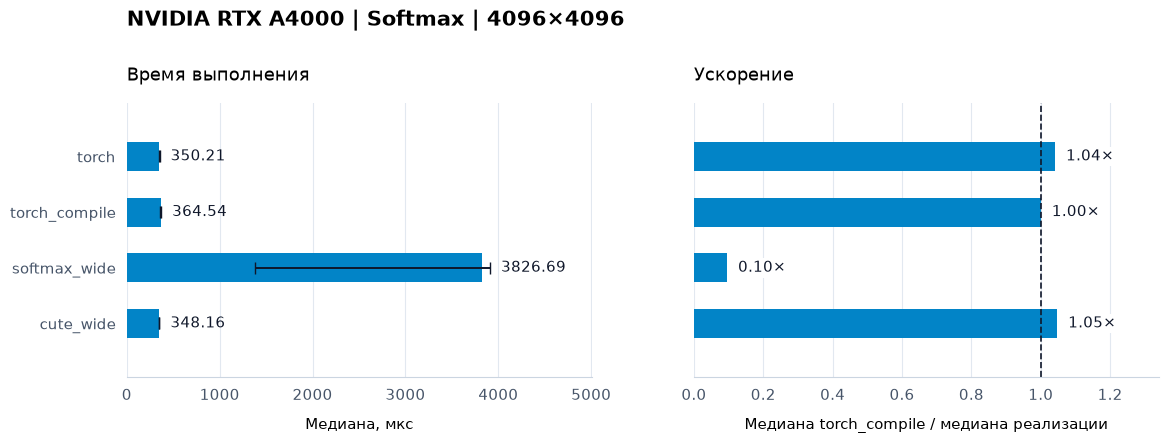

In [5]:
inputs = make_softmax_inputs(M, N)
# Условная оценка на элемент учитывает максимум, вычитание, exp, сложение и деление.
results = run_benchmark(implementations, inputs, reference=softmax_reference, flops=5 * M * N)
plot_benchmark(
    results, baseline="torch_compile",
    title=f"{torch.cuda.get_device_name(device)} | Softmax | {M}×{N}",
)
plt.show()

## PTX и SASS

In [6]:
for name, fn in implementations.items():
    assembly = fn.asm()
    dump_asm(assembly, Path("asm") / name)
    print(name, list(assembly))

torch []
torch_compile ['triton_red_fused__softmax_prepare_softmax_online_0']
softmax_wide []
cute_wide ['softmax_wide']
